In [41]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import src.configs.config as cfg
import src.configs.comon as comon
import os
import time
from src.plotting import create_and_save_table, create_config_table, plot_variance_vs_param
from src.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       get_sin_signal, 
                       calculate_complex_stiring_matrix,calculate_complex_stiring_vector,
                       calculate_full_bartlett_values, calculate_full_capon_values, get_analytical_sin_signal
                       )
from src.functions import (

                       calculate_bartlett_values,
                       get_impulse_signal, get_noise, 
                       calculate_noise_level, 
                       calculate_energy,
                       get_avp_signals, 
                       calculate_stiring_matrix, 
                       get_est_phi,
                       calculate_capon_values,
                       calculate_fft, 
                       calculate_f_rms, 
                       filtering_spectrum, 
                       calculate_ifft, 
                       calculate_stiring_vector
                       )
from src.experiments import (stat_vs_params, calculate_variance)
config_parametrs = cfg.init_rng()
path = "attachment/images/notebook"
os.makedirs(path,exist_ok=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [42]:
from scipy.signal import hilbert
sin_signal = get_sin_signal(config_parametrs)
# Преобразование гильберта возращает уже весь аналитический сигнал (real + imag)
# hilbert(s(t)) = s(t) + h(s(t)) 
z = hilbert(sin_signal) # массив комлпексных значенйи 

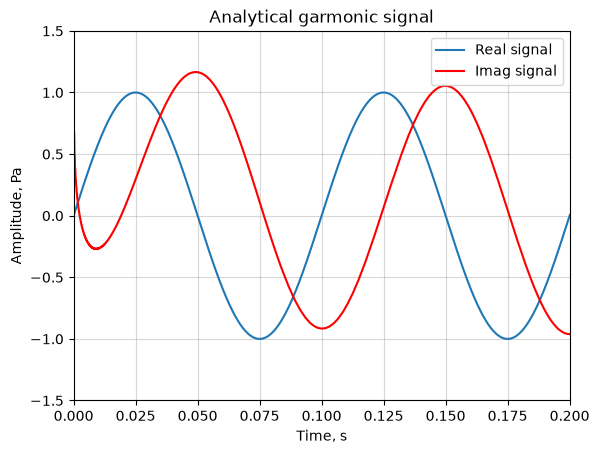

In [43]:

plt.plot(config_parametrs["time_vector"], z.real, label = "Real signal")
plt.plot(config_parametrs["time_vector"], z.imag, color = "red", label = "Imag signal")
plt.legend()
plt.xlabel("Time, s")
plt.title("Analytical garmonic signal")
plt.ylabel("Amplitude, Pa")
plt.xlim(0,0.2)
plt.ylim(-1.5, 1.5)
plt.grid(True, alpha = 0.5)

In [44]:
tau_array = get_tau_array(config_parametrs)
channel_real_matrix = get_channel_matrix(config_parametrs, tau_array, get_sin_signal)
channel_complex_matrix = get_channel_matrix(config_parametrs, tau_array, get_analytical_sin_signal)

w_real = get_covariation_matrix(channel_real_matrix, config_parametrs["N"])
w_complex = get_covariation_matrix(channel_complex_matrix, config_parametrs["N"])
dir_complex_matrix = calculate_complex_stiring_matrix(config_parametrs)



bartlett_real = calculate_full_bartlett_values(w_real, dir_complex_matrix)
bartlett_complex = calculate_full_bartlett_values(w_complex, dir_complex_matrix)


print(np.array_equal(bartlett_real, bartlett_complex))

False


d:\Разработка\vscode projects\piling-main\src\functions.py:120: ComplexWarning: Casting complex values to real discards the imaginary part
  return rng.normal(loc=0, scale=noise_level, size=config_parametrs["N"])
d:\Разработка\vscode projects\piling-main\src\functions.py:210: ComplexWarning: Casting complex values to real discards the imaginary part
  channel_matrix[idx * 3 : idx * 3 + 3] = sensor_matrix


In [45]:


complex_e_max = max(bartlett_complex)
complex_est_phi = get_est_phi(config_parametrs["phi_vector"], bartlett_complex) 


real_e_max = max(bartlett_real)
real_est_phi = get_est_phi(config_parametrs["phi_vector"], bartlett_real) 


print((complex_est_phi*180) / np.pi)
print((real_est_phi*180) / np.pi)


60.105045360496575
60.16234282985834


d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1811: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
d:\Разработка\vscode projects\piling-main\.env\Lib\site-packages\matplotlib\cbook.py:1408: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asanyarray(x, float)


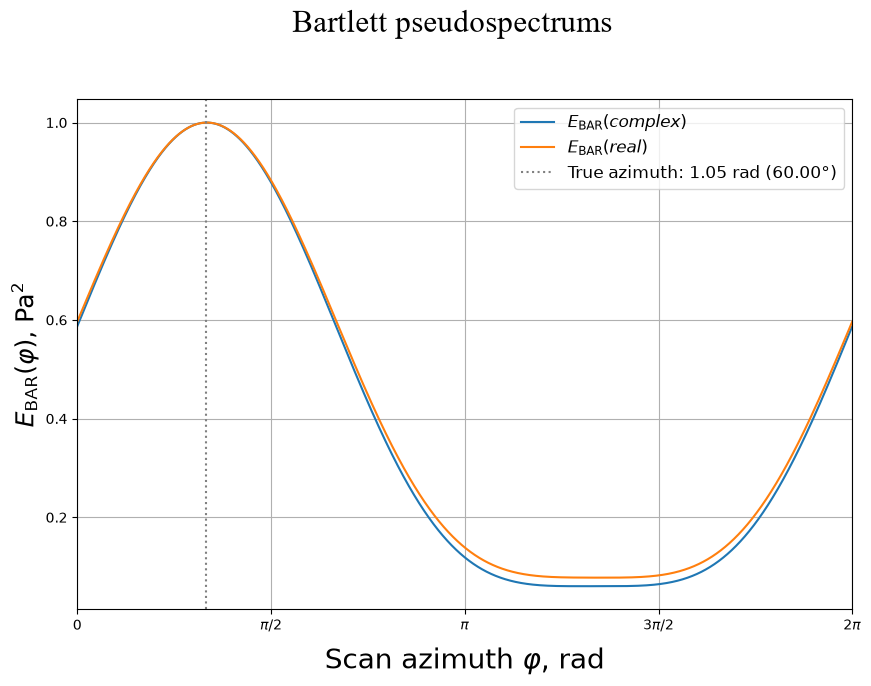

In [46]:
title_main = "Bartlett pseudospectrums"


fig, ax = plt.subplots(figsize = (10,10))
fig.subplots_adjust(top=0.85, bottom=0.34)

# Функция Бартлетта и отметки углов.
ax.plot(
    config_parametrs["phi_vector"], bartlett_complex / complex_e_max,
    label=r"$E_{\mathrm{BAR}} (complex)$"
)
ax.plot(
    config_parametrs["phi_vector"], bartlett_real / real_e_max,
    label=r"$E_{\mathrm{BAR}} (real)$",
)
ax.axvline(
    config_parametrs["target_phi"], color="gray", linestyle=":",
    label=f"True azimuth: {config_parametrs["target_phi"]:.2f} rad ({np.degrees(config_parametrs["target_phi"]):.2f}°)"
)
# Названия осей и заголовок
fig.suptitle(
    title_main,
    y=0.925, va="center",
    fontfamily="Times New Roman", fontsize=22
)

ax.set_xlabel(r"Scan azimuth $\varphi$, rad", labelpad=10, fontsize=20)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, Pa$^2$", fontsize=18)

ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"]
)

ax.set_xlim(0, 2 * np.pi)
ax.legend(loc="upper right", fontsize=12)
ax.grid(True)


In [47]:
config_random = dict( # noqa: C408
                    is_CRN = True, 
                    is_random_start = False)

config_bartlett_for_real_signal = dict(  # noqa: C408
                            energy_func = calculate_bartlett_values,
                            signal_func = get_sin_signal,
                            stiring_func = calculate_stiring_matrix,
                            **config_random)
config_bartlett_for_complex_signal  = dict(  # noqa: C408
                            energy_func = calculate_full_bartlett_values,
                            signal_func = get_analytical_sin_signal,
                            stiring_func = calculate_complex_stiring_matrix,
                            **config_random)

In [48]:
config_parametrs1 = cfg.restart_rng(config_parametrs)
config_parametrs2 = config_parametrs1
start_time = time.perf_counter()

parametr_config = dict(  # noqa: C408
    parametr_name = "target_phi",
    parametr_values = cfg.PHI_VALUES) 
var_bartlett_vs_phis = stat_vs_params(config_params=config_parametrs1,
                                     stat_func = calculate_variance,
                                   **config_bartlett_for_real_signal,
                                   **parametr_config)
var_bartlett_vs_phis_complex = stat_vs_params(config_params = config_parametrs2,
                                             stat_func = calculate_variance,
                                             **config_bartlett_for_complex_signal,
                                             **parametr_config)
var_delta_abs = np.abs(np.array(var_bartlett_vs_phis) - np.array(var_bartlett_vs_phis_complex))
end_time = time.perf_counter()
delta_time = end_time - start_time

d:\Разработка\vscode projects\piling-main\src\functions.py:120: ComplexWarning: Casting complex values to real discards the imaginary part
  return rng.normal(loc=0, scale=noise_level, size=config_parametrs["N"])
d:\Разработка\vscode projects\piling-main\src\functions.py:210: ComplexWarning: Casting complex values to real discards the imaginary part
  channel_matrix[idx * 3 : idx * 3 + 3] = sensor_matrix


(<Figure size 1400x1100 with 1 Axes>,
 <Axes: xlabel='Source azimuth $\\varphi_0$, deg', ylabel='$s_{\\varepsilon}^{2}$, deg$^2$'>)

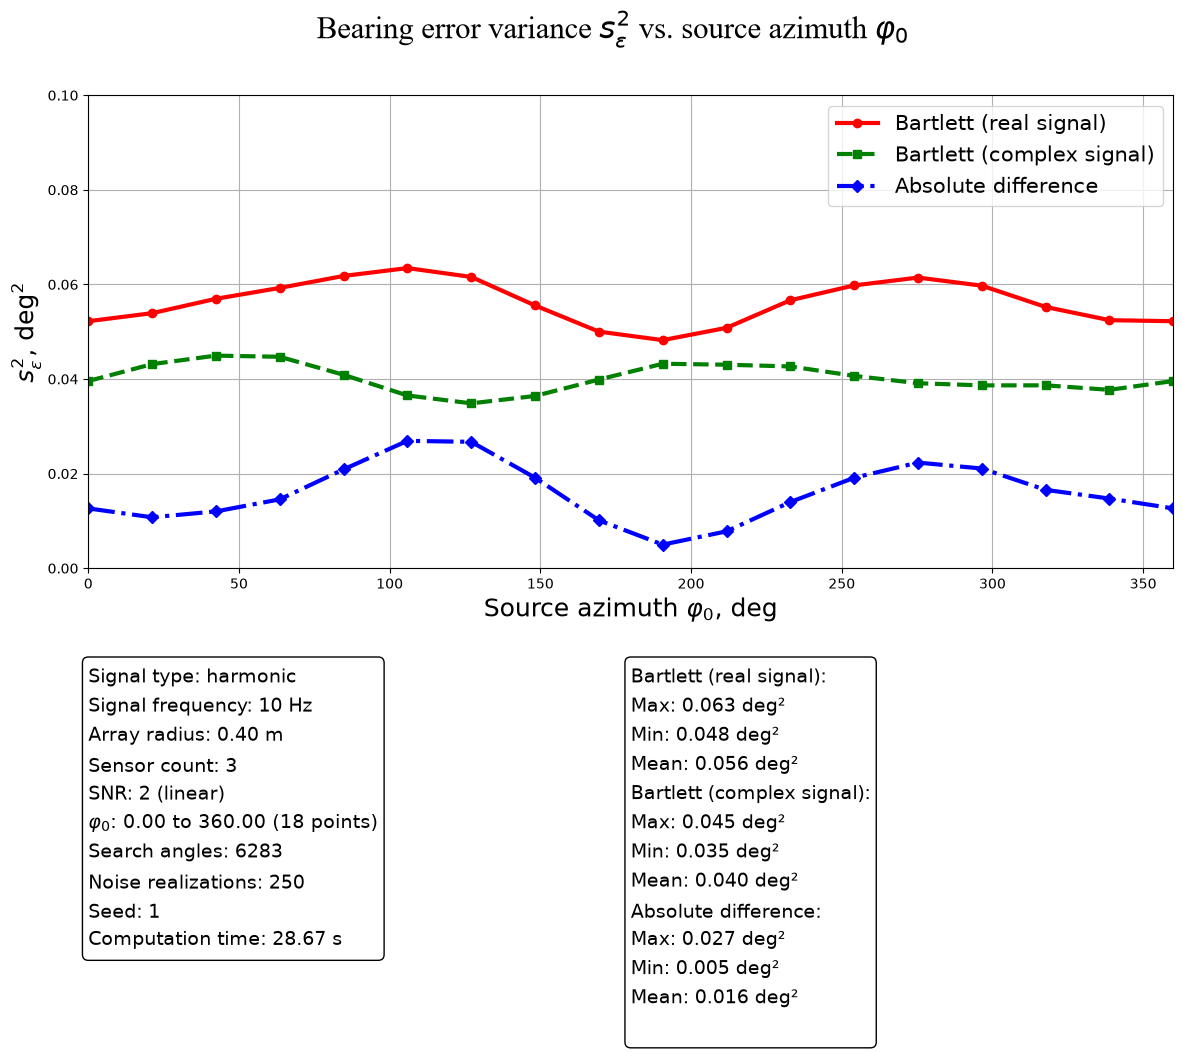

In [49]:
plot_variance_vs_param(dict_values = {"Bartlett (real signal)": var_bartlett_vs_phis,
                                      "Bartlett (complex signal)": var_bartlett_vs_phis_complex,
                                      "Absolute difference": var_delta_abs},
                       config_params = config_parametrs.copy(),
                       delta_time = delta_time,
                       ylim = (0.00*comon.CONST_RADIAN, 0.1*comon.CONST_RADIAN),
                       xlim = (0,360),
                       type_signal = "garmonic",
                       **parametr_config)